# 02 Exploratory data analysis

What the cleaned Google Play reviews of Tabby and Tamara look like before any modeling:
volume, ratings, language, length, developer replies, and the words that separate
negative from positive reviews.

All logic lives in `src/clean/` and `src/analysis/`; this notebook only calls it.
Build the clean dataset first:
```
python -m src.clean.pipeline
```
Figures are saved to `reports/figures/eda_*.png`. Numbers in the text are from the
collection of 2026-11-15.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import pandas as pd

from src.analysis import eda as E
from src.analysis.plots import (
    app_color, app_name, caption, grouped_bars, lines_by_app, save, setup_style, terms_panel,
)
from src.config import get_path, set_seed

set_seed()
setup_style()
pd.set_option("display.width", 160)

df = E.load_clean()                     # Google Play, the main dataset
df_rss = E.load_clean("app_store_rss")  # App Store, recent reviews only
SOURCE_NOTE = "Source: Google Play reviews, country sa, collected 2026-11-15."
df.shape

(183341, 26)

## 1. Cleaning summary

The pipeline removes very little. Only 2 rows were true double submissions, and 176 had no
usable content (punctuation, numbers, single letters, or scripts other than Arabic / Latin,
such as Bengali "ভালো"). Repeated *text* is not treated as a duplicate: thousands of different
people wrote "جيد" or "👍", and each is a real opinion.

In [2]:
pd.read_csv(get_path("cleaning_log"))

,step,reason,removed,rows_after
0,loaded,all raw files,0,184501
1,duplicate_id,same review collected twice (source + review_id),0,184501
2,double_submission,"same app, text, rating and timestamp",2,184499
3,empty,no text at all,0,184499
4,no_content,fewer than 2 Arabic/Latin letters and no emoji...,176,184323


## 2. Overview

Ratings are very high for both apps on Google Play, and the App Store RSS sample
(recent reviews only) is much more negative. That gap is a reminder that Google Play
averages are inflated by very short 5-star reviews (section 5).

In [3]:
E.overview(df)

,reviews,first_month,last_month,mean_rating,share_negative,share_arabic,reply_rate
app,,,,,,,
tabby,119338,2020-10,2026-11,4.6,0.077,0.455,0.556
tamara,64003,2021-04,2026-11,4.65,0.065,0.597,0.108


In [4]:
E.overview(df_rss).drop(columns="reply_rate")  # the RSS feed has no reply data

,reviews,first_month,last_month,mean_rating,share_negative,share_arabic
app,,,,,,
tabby,494,2026-06,2026-11,3.7,0.314,0.650
tamara,488,2025-10,2026-11,3.13,0.457,0.766


## 3. Language

Language was detected from the text, not taken from the store's language bucket.
The `en` bucket turned out to be mostly English after all (95%), but each bucket
still holds about 2,000 reviews in the other language. **Arabizi** (Arabic in Latin
letters, like "7lw") came out at **zero**: early rules flagged English reviews that
used "mashallah" or "inshallah", which were removed from the word list. Saudi reviewers
write Arabic in Arabic script.

Tabby's reviews are about half English and Tamara's are 60% Arabic.

In [5]:
E.language_vs_query(df)

lang,arabic,emoji_only,english,mixed,All
lang_query,,,,,
ar,90565,2806,2653,65,96089
en,1921,2014,83270,47,87252
All,92486,4820,85923,112,183341


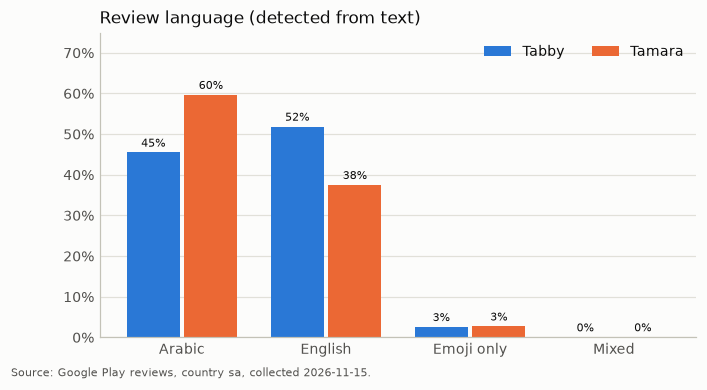

In [6]:
mix = E.language_mix(df)
fig, ax = plt.subplots(figsize=(7, 3.6))
grouped_bars(ax, mix, fmt="{:.0%}", xlabels=["Arabic", "English", "Emoji only", "Mixed"])
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
ax.set_ylim(0, 0.75)
ax.set_title("Review language (detected from text)")
caption(fig, SOURCE_NOTE)
save(fig, "eda_language_mix");

## 4. Volume and sentiment over time

Reviews are split by stars: 1–2 negative, 4–5 positive (3 = neutral, not shown).
**Counts**, not shares, are plotted so that a change in how many happy users review
cannot hide or fake a change in complaints. The incomplete current month is left out.

Two things stand out:

1. **Tamara, February 2026:** positive reviews fall about 90% (from about 2,200 a month to
   about 190), while negative reviews fall much less, about 35% (from 113 to 72 a month). So
   Tamara's average rating drops from about 4.7 to about 3.9 mainly because of **who is
   reviewing**, not because more people complain. A likely (unconfirmed) explanation is that the app stopped asking satisfied
   users for a rating. This matters for Phase 5: a share-based sentiment index would show
   a crash for Tamara that the complaint counts don't support.
2. **Tabby, July–August 2026:** negative reviews jump to 371 and 562 a month (normally
   about 150–230). This is a candidate to check against `events.csv` in Phase 5.

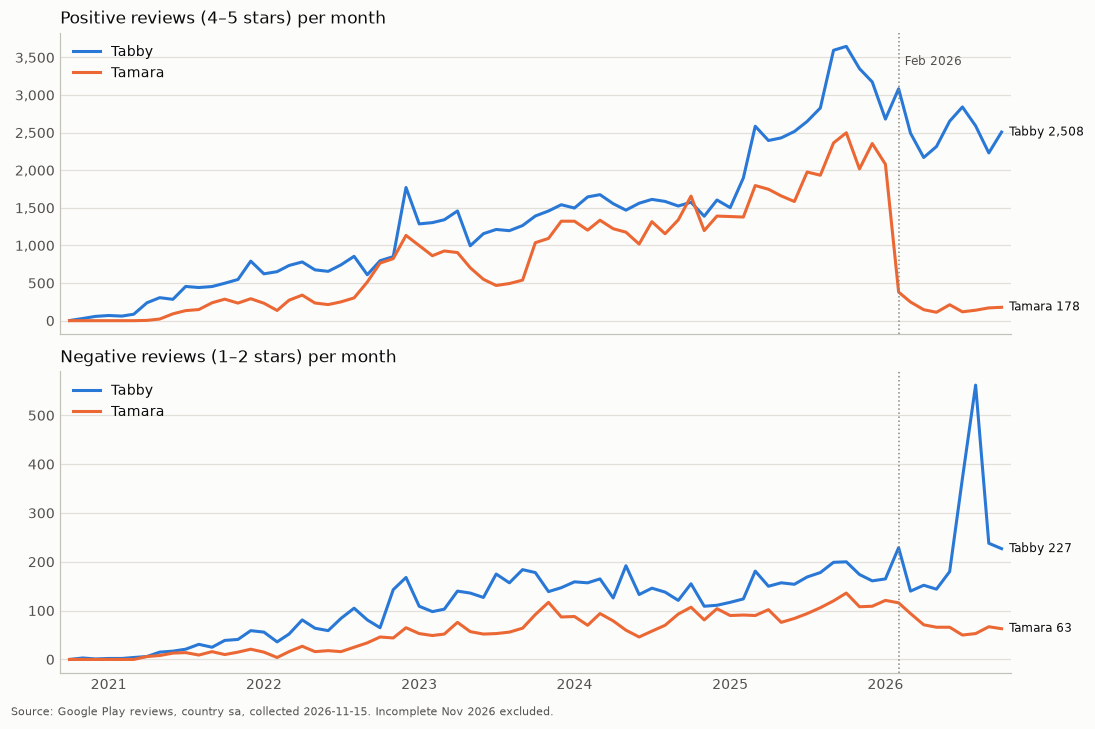

In [7]:
last_full = df["month"].max()  # partial month at collection time
pos = E.monthly_by_sentiment(df, "positive").loc[lambda t: t.index < last_full]
neg = E.monthly_by_sentiment(df, "negative").loc[lambda t: t.index < last_full]

fig, axes = plt.subplots(2, 1, figsize=(10, 6.6), sharex=True)
lines_by_app(axes[0], pos)
axes[0].set_title("Positive reviews (4–5 stars) per month")
lines_by_app(axes[1], neg)
axes[1].set_title("Negative reviews (1–2 stars) per month")
for ax in axes:
    ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
    ax.axvline(pd.Timestamp("2026-02-01"), color="#898781", linestyle=":", linewidth=1)
axes[0].annotate("Feb 2026", (pd.Timestamp("2026-02-01"), 3400),
                 xytext=(4, 0), textcoords="offset points", ha="left", fontsize=8, color="#52514e")
caption(fig, SOURCE_NOTE + " Incomplete Nov 2026 excluded.")
fig.tight_layout(rect=(0, 0.02, 1, 1))
save(fig, "eda_reviews_by_sentiment");

In [8]:
# The same break in numbers: Tamara before vs. after Feb 2026
t = df[(df["app"] == "tamara") & (df["month"] >= "2025-07-01") & (df["month"] < last_full)]
t.groupby(t["month"] >= "2026-02-01").agg(
    months=("month", "nunique"),
    reviews_per_month=("review_id", lambda s: round(len(s) / t.loc[s.index, "month"].nunique())),
    mean_rating=("rating", "mean"),
    positives_per_month=("sentiment", lambda s: round((s == "positive").sum() / t.loc[s.index, "month"].nunique())),
    negatives_per_month=("sentiment", lambda s: round((s == "negative").sum() / t.loc[s.index, "month"].nunique())),
).rename(index={False: "Jul 2025 - Jan 2026", True: "Feb 2026 - Oct 2026"}).round(2)

,months,reviews_per_month,mean_rating,positives_per_month,negatives_per_month
month,,,,,
Jul 2025 - Jan 2026,7,2336,4.72,2175,113
Feb 2026 - Oct 2026,9,268,3.86,189,72


## 5. Ratings and review length

About 85% of reviews are 5 stars and only 6–7% are 1 star. Positive reviews are tiny:
the median 4–5 star review is **2 words** ("ممتاز", "good app"), while the median 1-star
review is 12–13 words. For modeling this means:
- classes are very imbalanced, so report **macro-F1**, not accuracy;
- most of the actual text (and most of the signal about *what* goes wrong) sits in the
  negative reviews.

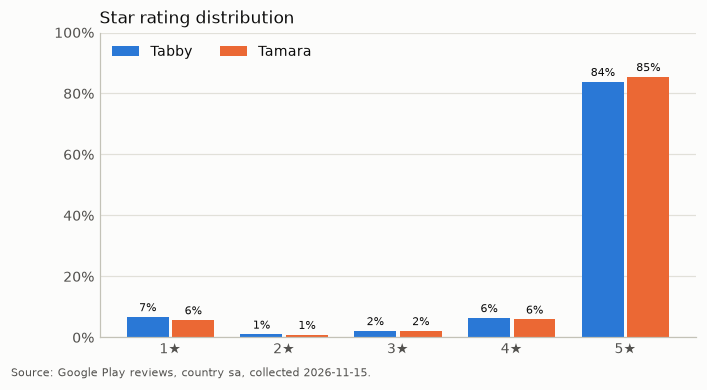

In [9]:
dist = E.rating_distribution(df)
fig, ax = plt.subplots(figsize=(7, 3.6))
grouped_bars(ax, dist, fmt="{:.0%}", xlabels=[f"{s}★" for s in dist.index], legend_loc="upper left")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
ax.set_ylim(0, 1)
ax.set_title("Star rating distribution")
caption(fig, SOURCE_NOTE)
save(fig, "eda_rating_distribution");

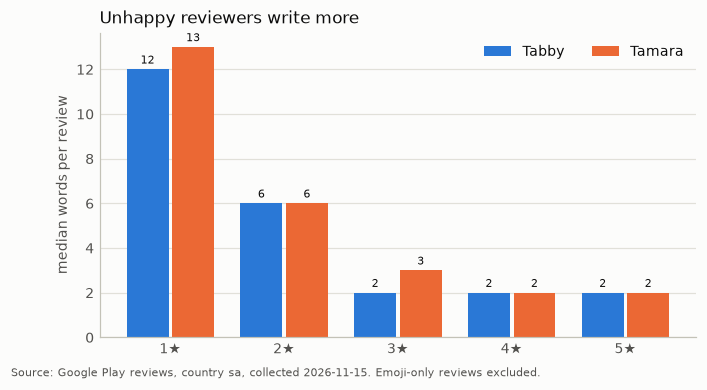

In [10]:
length = E.length_by_rating(df)
fig, ax = plt.subplots(figsize=(7, 3.6))
grouped_bars(ax, length, fmt="{:.0f}", xlabels=[f"{s}★" for s in length.index])
ax.set_ylabel("median words per review")
ax.set_title("Unhappy reviewers write more")
caption(fig, SOURCE_NOTE + " Emoji-only reviews excluded.")
save(fig, "eda_length_by_rating");

## 6. Developer replies

The headline "Tabby replies to 56% of reviews, Tamara to 11%" is misleading on its own.
Broken down by rating, **both apps reply to about 87–92% of 1–2 star reviews**. The gap
comes from positive reviews: Tabby replies to about half of its 4–5 star reviews, Tamara to
almost none. Tabby's reply rate also changed over time, from under 10% before 2024 to
98% in 2026, which suggests a change in policy (likely automated or templated replies to
positive reviews).

Tamara answers faster: median **under 1 hour** vs. about **22 hours** for Tabby.
(Reply dates are the latest edit of a reply, so times are upper bounds.)

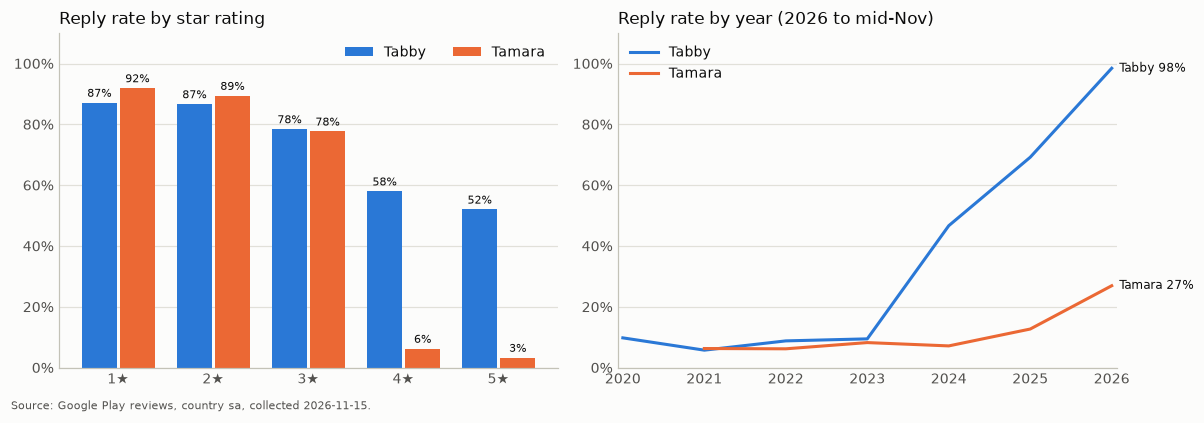

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
by_rating = E.reply_by_rating(df).astype(float)
grouped_bars(axes[0], by_rating, fmt="{:.0%}", xlabels=[f"{s}★" for s in by_rating.index])
axes[0].set_title("Reply rate by star rating")
axes[0].set_ylim(0, 1.1)
by_year = E.reply_by_year(df).astype(float)
lines_by_app(axes[1], by_year, fmt="{:.0%}")
axes[1].set_title("Reply rate by year (2026 to mid-Nov)")
axes[1].set_ylim(0, 1.1)
axes[1].set_xticks(by_year.index)
for ax in axes:
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
caption(fig, SOURCE_NOTE)
fig.tight_layout(rect=(0, 0.03, 1, 1))
save(fig, "eda_developer_replies");

In [12]:
E.reply_time(df)

,replied,median_h,p75_h,p90_h,within_24h
app,,,,,
tabby,65518,22.4,99.5,379.6,0.515
tamara,6723,0.8,29.4,47.5,0.648


## 7. What separates negative from positive reviews

Words and two-word phrases are ranked by the **weighted log-odds ratio with an informative
Dirichlet prior** (Monroe, Colaresi & Quinn, 2008). Unlike raw counts, it down-weights
words common to both groups and gives a z-score, so rare words don't dominate. Only phrases
in at least 30 reviews and with z ≥ 2 are shown. Arabic and English reviews are ranked
separately.

Early complaint themes (to be confirmed by topic modeling in Phase 4):
- **Customer service** is the top negative phrase for both apps in both languages
  ("خدمه العملاء", "customer service").
- **Tabby:** app updates breaking the app ("التحديث الاخير", "صفحه بيضاء" / "شاشه بيضاء" = blank
  white screen), blocked cards, late fees.
- **Tamara:** late fees and penalties ("رسوم التاخير", "غرامه التاخير"), the first payment
  ("الدفعه الاولي"), refunds and amounts.
- Positive reviews are generic praise: excellent service, easy to use, thanks.

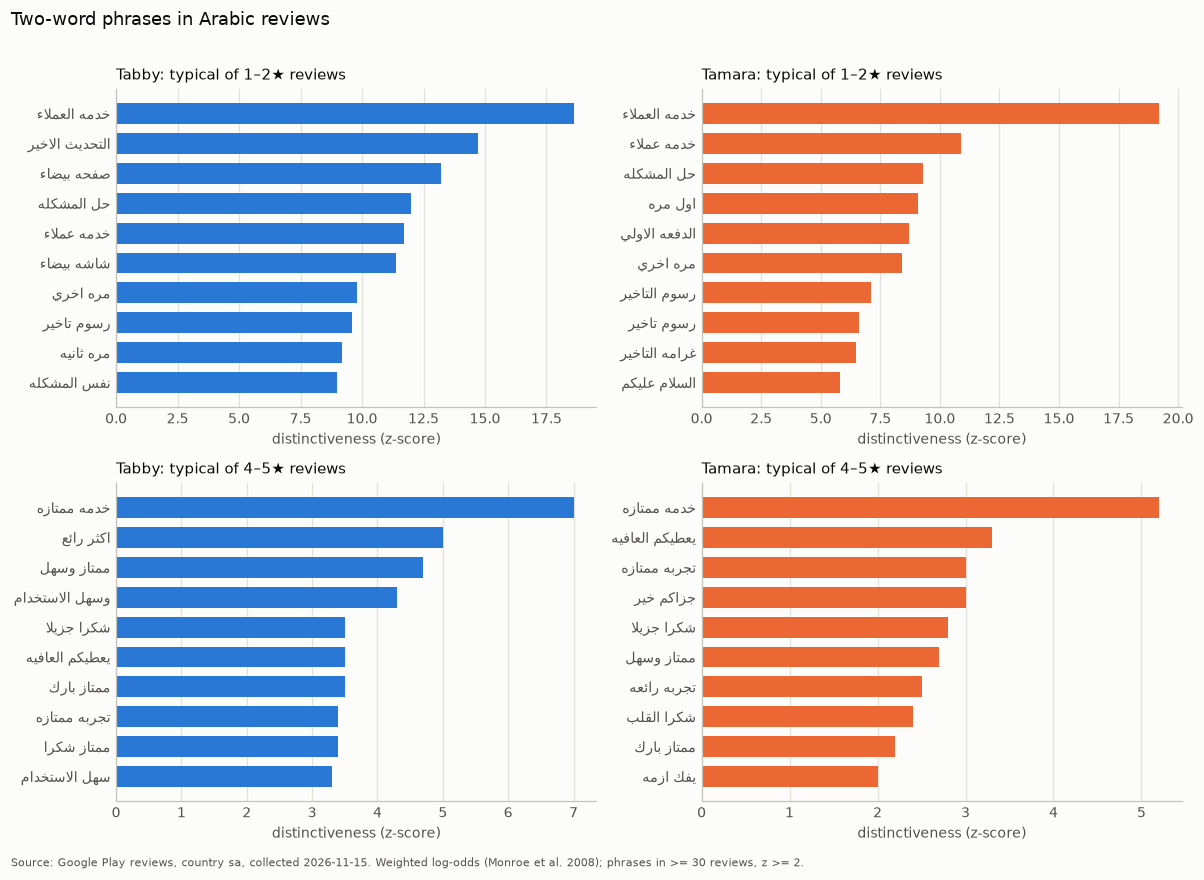

In [13]:
def terms_figure(script: str, name: str, title: str) -> plt.Figure:
    fig, axes = plt.subplots(2, 2, figsize=(11, 8))
    for col, app in enumerate(["tabby", "tamara"]):
        t = E.distinctive_terms(df, app, script, n=2, top_n=10)
        t = t[t["z"] >= 2]
        for row, side in enumerate(["negative", "positive"]):
            label = "1–2★" if side == "negative" else "4–5★"
            terms_panel(axes[row, col], t[t["side"] == side], app_color(app),
                        f"{app_name(app)}: typical of {label} reviews")
    fig.suptitle(title, x=0.01, ha="left", fontsize=12)
    caption(fig, SOURCE_NOTE + " Weighted log-odds (Monroe et al. 2008); phrases in >= 30 reviews, z >= 2.")
    fig.tight_layout(rect=(0, 0.02, 1, 0.97))
    save(fig, name)
    return fig

terms_figure("arabic", "eda_terms_arabic", "Two-word phrases in Arabic reviews");

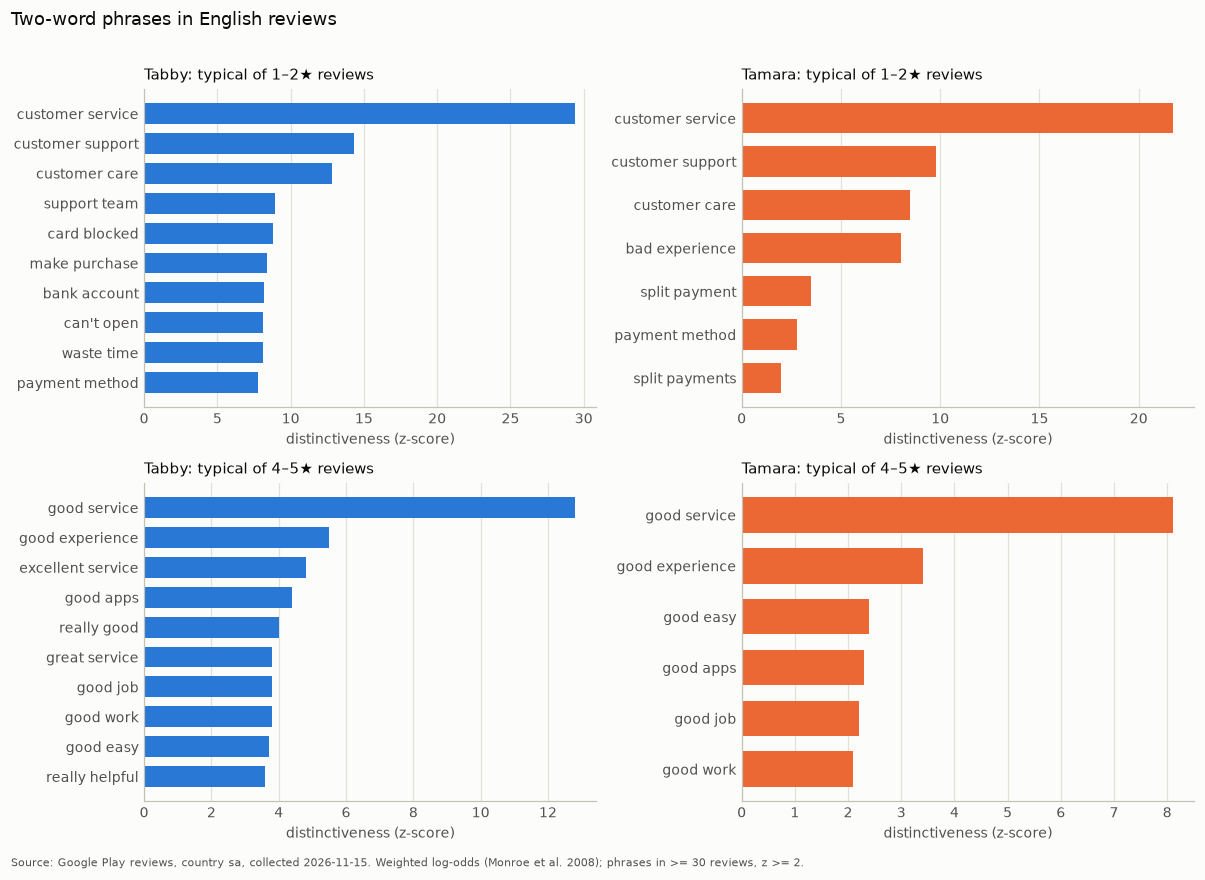

In [14]:
terms_figure("english", "eda_terms_english", "Two-word phrases in English reviews");

## 8. Emoji

Emoji are kept as a feature. Negative reviews use different emoji, so they carry
sentiment signal even when the text is short.

In [15]:
pd.concat(
    {s: E.top_emojis(df, s, n=8).groupby("app")["emoji"].apply("".join) for s in ["negative", "positive"]},
    axis=1,
)

,negative,positive
app,,
tabby,👍👎😡😔😭😕😂👎🏻,👍❤️😊😍👌🥰💯🌹
tamara,👎👍😡👎🏻😔😭😞💔,👍❤️😊👌😍🥰🌹💯


## 9. Takeaways for the next phases

| Finding | Consequence |
|---|---|
| 85% of reviews are 5 stars; positive reviews are ~2 words | Use macro-F1 and class weights in Phase 3; the gold set should over-sample negative and neutral reviews |
| Tamara's positive reviews fell ~90% in Feb 2026, complaints only ~35% | In Phase 5, report complaint **counts** next to the share-based sentiment index, and flag Feb 2026 as a change in who reviews |
| Tabby negative spike Jul–Aug 2026 | Look for a matching event when filling `events.csv` |
| Both apps reply to ~90% of complaints; Tabby also replies to positives since 2024 | "Reply rate" must be compared by rating, not overall |
| Top complaints: customer service, update bugs (Tabby), late fees / first payment (Tamara) | Starting topic list for Phase 4 |
| Arabizi is essentially absent; 52% / 38% of reviews are English | Models must handle Arabic **and** English; CAMeLBERT alone only covers Arabic |
| Emoji-only reviews (2.6%) | Kept for EDA, excluded from text-model training (`trainable = False`) |